# Model Experiments: Top-N Game Recommendation

This notebook compares the recommenders implemented in `src/components/recommenders` on the **validation** split and
looks at where each one works well. It reuses the processed data and artifacts written by the training pipeline:

```bash
python -m src.pipeline.training_pipeline
```

**Setup recap**
- Each user's most recent review is the *test* target and the one before it is the *validation* target. Everything
  older is used for training.
- Only liked games (`is_recommended = True`) count as relevant. Every game a user already reviewed is excluded from their list.
- Metrics are computed at K = 10 over users whose held-out game is a liked one.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.components.data_transformation import DataTransformation
from src.components.model_evaluation import evaluate_model, users_with_targets
from src.components.recommenders import build_model
from src.configuration.configuration import ConfigurationManager
from src.constant import EVALUATION_REPORT_FILE, TUNING_REPORT_FILE
from src.utils.common import load_json
from src.utils.metrics import hit_matrix, ranking_metrics

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 4)
warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm notice from `implicit`

## 1. Load the Processed Splits

In [2]:
config = ConfigurationManager()
transform_cfg = config.get_data_transformation_config()
trainer_cfg = config.get_model_trainer_config()

data = DataTransformation.load(transform_cfg.processed_dir, transform_cfg.artifacts_dir)

summary = pd.DataFrame({
    split: {"interactions": len(df), "users": df["user_idx"].nunique(), "liked share": df["is_recommended"].mean()}
    for split, df in {"train": data.train, "val": data.val, "test": data.test}.items()
}).T
print(f"{data.n_users:,} users x {data.n_items:,} games")
summary

182,790 users x 5,711 games


,interactions,users,liked share
train,966975.0,182790.0,0.8581
val,182790.0,182790.0,0.8605
test,182790.0,182790.0,0.8514


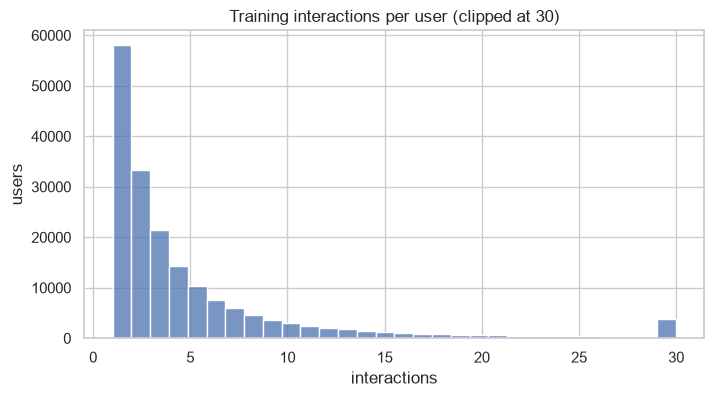

In [3]:
train_counts = data.train.groupby("user_idx").size()
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(train_counts.clip(upper=30), bins=30, ax=ax)
ax.set(title="Training interactions per user (clipped at 30)", xlabel="interactions", ylabel="users")
plt.show()

## 2. Baseline Comparison on Validation

Every model is fitted on the training split with its default parameters from `config.yaml` and scored on the same
sample of validation users.

In [4]:
history, seen = data.matrices(data.train)
target, _ = data.matrices(data.val)

rng = np.random.default_rng(trainer_cfg.random_state)
val_users = users_with_targets(target)
val_users = np.sort(rng.choice(val_users, min(trainer_cfg.tuning_sample_users, len(val_users)), replace=False))

models = {name: build_model(name, **(spec.get("params") or {})).fit(history, data.items)
          for name, spec in trainer_cfg.models.items()}

val_results = pd.DataFrame({name: evaluate_model(model, history, seen, target, val_users, k=10)
                            for name, model in models.items()}).T
val_results.sort_values("ndcg", ascending=False)

,hit_rate,precision,recall,ndcg,map,coverage
item_knn,0.0968,0.0097,0.0968,0.0536,0.0404,0.8823
als,0.0950,0.0095,0.0950,0.0511,0.0378,0.1219
popularity,0.0471,0.0047,0.0471,0.0231,0.0159,0.0040
content,0.0190,0.0019,0.0190,0.0116,0.0093,0.8375


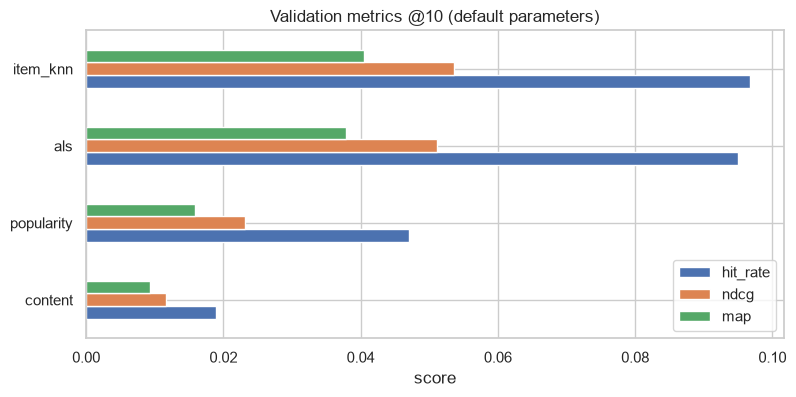

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
val_results[["hit_rate", "ndcg", "map"]].sort_values("ndcg").plot.barh(ax=ax)
ax.set(title="Validation metrics @10 (default parameters)", xlabel="score")
plt.show()

## 3. Effect of List Length K

The top 50 is computed once per model and then cut to smaller K. A longer list catches more held-out games, but
users mostly see the first few results.

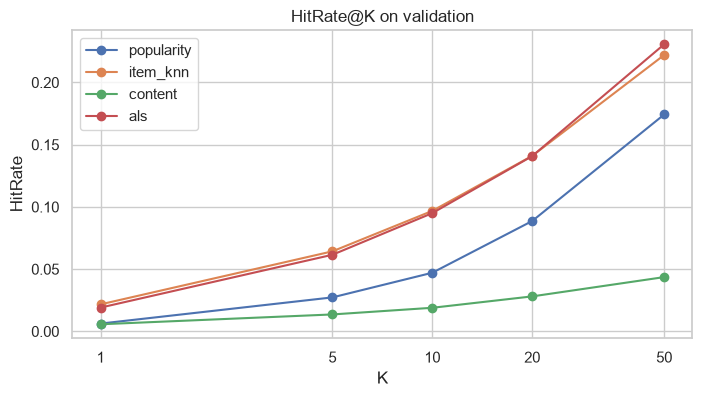

,popularity,item_knn,content,als
1,0.0063,0.0217,0.0057,0.0191
5,0.0273,0.0643,0.0136,0.0615
10,0.0471,0.0968,0.0190,0.0950
20,0.0887,0.1410,0.0281,0.1408
50,0.1743,0.2220,0.0436,0.2306


In [6]:
K_VALUES = [1, 5, 10, 20, 50]

def metrics_by_k(model, users, batch_size=2048):
    hits, n_rel = [], []
    for start in range(0, len(users), batch_size):
        batch = users[start:start + batch_size]
        recs, _ = model.recommend(history[batch], k=max(K_VALUES), exclude=seen[batch], user_idx=batch)
        relevant = target[batch].toarray() > 0
        hits.append(hit_matrix(recs, relevant))
        n_rel.append(relevant.sum(axis=1))
    hits, n_rel = np.vstack(hits), np.concatenate(n_rel)
    return {k: ranking_metrics(hits[:, :k], n_rel)["hit_rate"].mean() for k in K_VALUES}

hit_by_k = pd.DataFrame({name: metrics_by_k(model, val_users) for name, model in models.items()})

fig, ax = plt.subplots(figsize=(8, 4))
hit_by_k.plot(marker="o", ax=ax)
ax.set(title="HitRate@K on validation", xlabel="K", ylabel="HitRate", xscale="log", xticks=K_VALUES)
ax.set_xticklabels(K_VALUES)
plt.show()
hit_by_k

## 4. Performance by User Activity

Users with very short histories are the hardest case. Splitting validation users by their number of training
interactions shows which model to rely on for each group.

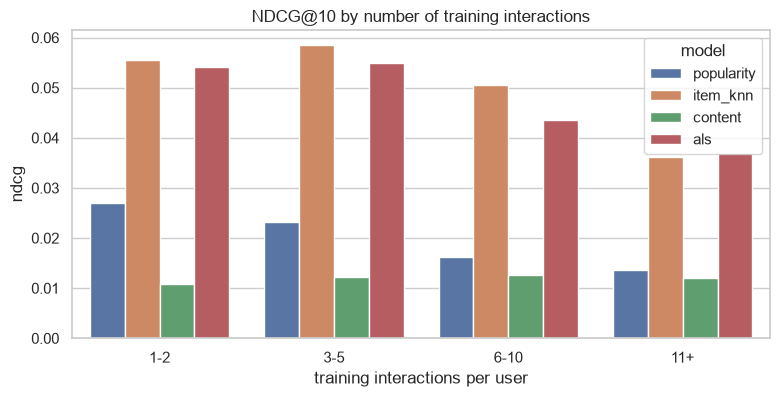

model,als,content,item_knn,popularity
1-2,0.0542,0.0108,0.0556,0.0269
3-5,0.0550,0.0123,0.0585,0.0231
6-10,0.0435,0.0127,0.0505,0.0161
11+,0.0370,0.0121,0.0362,0.0137


In [7]:
buckets = pd.cut(train_counts.reindex(val_users).fillna(0), bins=[0, 2, 5, 10, np.inf],
                 labels=["1-2", "3-5", "6-10", "11+"])

rows = []
for bucket in buckets.cat.categories:
    users = val_users[(buckets == bucket).to_numpy()]
    for name, model in models.items():
        ndcg = evaluate_model(model, history, seen, target, users, k=10)["ndcg"]
        rows.append({"history": bucket, "model": name, "ndcg": ndcg, "users": len(users)})
by_activity = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=by_activity, x="history", y="ndcg", hue="model", order=buckets.cat.categories, ax=ax)
ax.set(title="NDCG@10 by number of training interactions", xlabel="training interactions per user")
plt.show()
by_activity.pivot(index="history", columns="model", values="ndcg").reindex(buckets.cat.categories)

## 5. Hyperparameter Tuning Results

The training pipeline grid-searches each model on the validation split (`artifacts/tuning_results.json`).

In [8]:
tuning = load_json(transform_cfg.artifacts_dir / TUNING_REPORT_FILE)
def format_params(params):
    return ", ".join(f"{k}={v}" for k, v in params.items() if k not in ("random_state", "iterations"))

trials = pd.DataFrame([{"model": name, "params": format_params(trial["params"]),
                        **{m: trial["metrics"][m] for m in ("ndcg", "hit_rate", "coverage")}}
                       for name, result in tuning["models"].items() for trial in result["trials"]])
print(f"Selected on validation: {tuning['selected_model']}")
trials.sort_values(["model", "ndcg"], ascending=[True, False]).reset_index(drop=True)

Selected on validation: item_knn


,model,params,ndcg,hit_rate,coverage
0,als,"factors=64, regularization=1.0, alpha=5.0",0.0520,0.0968,0.1739
1,als,"factors=64, regularization=0.1, alpha=5.0",0.0510,0.0952,0.1746
2,als,"factors=32, regularization=1.0, alpha=5.0",0.0509,0.0956,0.1192
3,als,"factors=32, regularization=0.1, alpha=5.0",0.0502,0.0940,0.1184
4,als,"factors=64, regularization=1.0, alpha=15.0",0.0476,0.0887,0.2483
5,als,"factors=64, regularization=0.1, alpha=15.0",0.0468,0.0877,0.2486
6,als,"factors=32, regularization=1.0, alpha=15.0",0.0459,0.0874,0.1762
7,als,"factors=32, regularization=0.1, alpha=15.0",0.0453,0.0863,0.1765
8,als,"factors=64, regularization=0.1, alpha=40.0",0.0390,0.0735,0.3136
9,als,"factors=64, regularization=1.0, alpha=40.0",0.0387,0.0727,0.3119


## 6. Final Results on the Test Split

The tuned models are refitted on train + validation and scored on each user's most recent review
(`artifacts/evaluation_report.json`).

In [9]:
report = load_json(transform_cfg.artifacts_dir / EVALUATION_REPORT_FILE)
test_results = pd.DataFrame({name: r["metrics"] for name, r in report["models"].items()}).T
print(f"Selected on validation: {report['selected_model']}  |  test users: {report['n_users']:,}  |  K = {report['k']}")
test_results.sort_values("ndcg", ascending=False)

Selected on validation: item_knn  |  test users: 155,632  |  K = 10


,hit_rate,precision,recall,ndcg,map,coverage
item_knn,0.0985,0.0098,0.0985,0.0539,0.0404,0.9711
als,0.0963,0.0096,0.0963,0.0522,0.0389,0.1916
popularity,0.0426,0.0043,0.0426,0.0205,0.0138,0.0049
content,0.0181,0.0018,0.0181,0.0106,0.0083,0.8930


## 7. Sample Recommendations

In [10]:
titles = data.items.set_index("item_idx")["title"]
best = models[report["selected_model"]]

# A user with a few liked games in training and a liked game held out for validation
candidates = [u for u in val_users if 4 <= train_counts.get(u, 0) <= 8]
user = candidates[0]

liked = data.train[(data.train["user_idx"] == user) & data.train["is_recommended"]]["item_idx"]
held_out = data.val[data.val["user_idx"] == user]["item_idx"]
recs, _ = best.recommend(history[[user]], k=10, exclude=seen[[user]], user_idx=np.array([user]))

print("Liked in training:", ", ".join(titles[liked]))
print("Held-out game:    ", ", ".join(titles[held_out]))
pd.DataFrame({"rank": range(1, 11), "recommended": titles[recs[0]].values,
              "is_held_out": np.isin(recs[0], held_out)})

Liked in training: Rust, Arma 3, Subnautica, Killing Floor 2, Factorio
Held-out game:     Kenshi


,rank,recommended,is_held_out
0,1,Fallout 4,False
1,2,Space Engineers,False
2,3,The Forest,False
3,4,Kerbal Space Program,False
4,5,7 Days to Die,False
5,6,Wallpaper Engine,False
6,7,No Man's Sky,False
7,8,Borderlands 2,False
8,9,Cyberpunk 2077,False
9,10,RimWorld,False


In [11]:
# "Games like this": nearest neighbours from the content model (tags + description)
# Most-liked training game among those with tags (about 10% of games ship without metadata)
has_tags = data.items["tags"].apply(len).to_numpy() > 0
query = int(np.argmax(np.where(has_tags, history.getnnz(axis=0), -1)))
neighbors, scores = models["content"].similar_items(query, k=10)
print("Similar to:", titles[query])
pd.DataFrame({"game": titles[neighbors].values, "similarity": scores.round(3)})

Similar to: Unturned


,game,similarity
0,Nomad,0.368
1,Fallen Earth Classic,0.355
2,No More Room in Hell,0.347
3,SURVIVAL: Postapocalypse Now,0.337
4,Fear the Night - 恐惧之夜,0.331
5,State of Decay: YOSE,0.324
6,Tom Clancy’s The Division™,0.323
7,DeadPoly,0.316
8,Codename CURE,0.315
9,Miscreated,0.313


## 8. Conclusions

- **Item-KNN is the best model** on validation and on test (test NDCG@10 ≈ 0.054, HitRate@10 ≈ 9.8%). That is about
  2.6x the popularity baseline. It is the model saved for serving.
- **ALS is a close second** (test NDCG@10 ≈ 0.052) and catches up at longer lists (HitRate@50). However, it
  recommends from only ~19% of the catalogue, while Item-KNN covers ~97%. ALS leans towards popular games.
- **ALS prefers simple, heavily regularised settings** (64 factors, regularization 1.0, alpha 5). With a median of
  ~4 reviews per user there is little signal for many latent factors.
- **Content-based alone is weak** for ranking (NDCG@10 ≈ 0.011). Tags describe genre rather than taste, and ~10% of
  games have no tags or description. It is still useful for "similar games" and for cold start.
- **Users with long histories are harder to predict.** They have already reviewed the obvious picks, so their next
  game tends to be more niche.

**Next steps:** blend Item-KNN and ALS scores, use disliked games as explicit negatives, add a learning-to-rank
re-ranker (e.g. LightGBM LambdaRank) over candidate lists, and train on a larger user sample.